# 02 Unsupervised Student Profiles

This notebook groups students using only numeric features, without using dropout during clustering. PCA gives a simple 2D view, while KMeans creates interpretable student profiles.

### What and why
Load the data and select numeric academic, demographic, and financial variables. The target is kept only for describing clusters after they are created.

In [1]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from data_utils import load_data
from plot_utils import set_style, save_figure

set_style()
data = load_data()
numeric_features = [
    "Age at enrollment", "Admission grade", "Previous qualification (grade)",
    "Curricular units 1st sem (enrolled)", "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)", "Curricular units 2nd sem (enrolled)",
    "Curricular units 2nd sem (approved)", "Curricular units 2nd sem (grade)",
    "Unemployment rate", "Inflation rate", "GDP",
]
X = data[numeric_features].fillna(data[numeric_features].median())
X_scaled = StandardScaler().fit_transform(X)


### What and why
Scale the variables so a feature measured in large units does not dominate the distance calculation. PCA compresses the scaled data into two axes for plotting.

In [2]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print("Variance explained by PC1 and PC2:", pca.explained_variance_ratio_.round(3))


Variance explained by PC1 and PC2: [0.362 0.14 ]


### What and why
Try several values of k. The elbow plot shows diminishing within-cluster improvement; the silhouette score measures how separated and compact the clusters are.

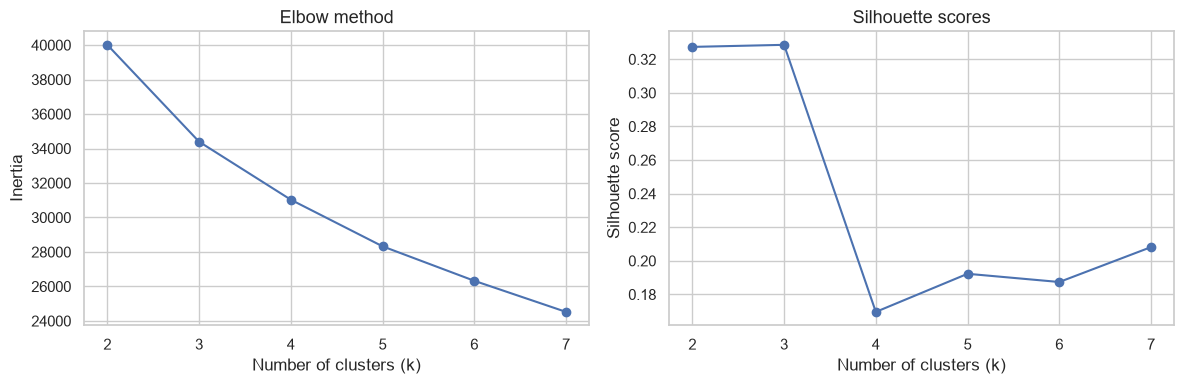

In [3]:
inertia = []
silhouettes = []
k_values = range(2, 8)
for k in k_values:
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)
    inertia.append(KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled).inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_values), inertia, marker="o")
axes[0].set(title="Elbow method", xlabel="Number of clusters (k)", ylabel="Inertia")
axes[1].plot(list(k_values), silhouettes, marker="o")
axes[1].set(title="Silhouette scores", xlabel="Number of clusters (k)", ylabel="Silhouette score")
save_figure("fig04_cluster_selection.png")
plt.show()


### What and why
Choose k=3 for a small, explainable set of profiles, then show the clusters in PCA space and calculate their actual dropout rates only for interpretation.

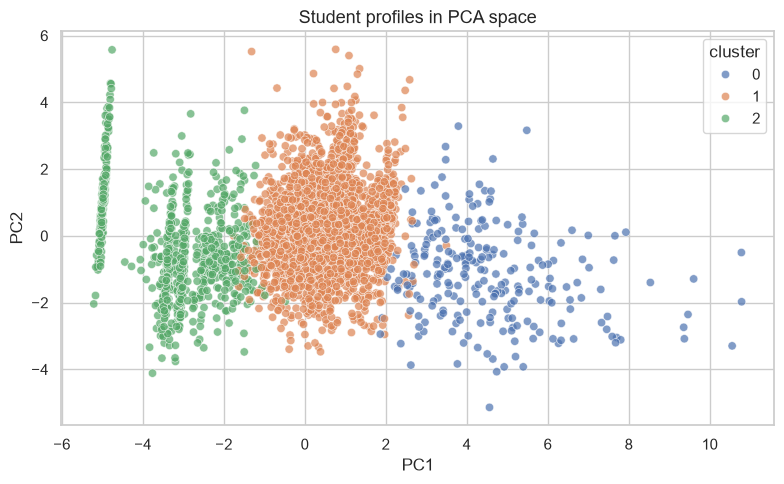

,students,dropout_rate,approved_1st,approved_2nd,grade_2nd,debtor_rate
cluster,,,,,,
0,240,0.20,12.26,10.62,12.70,0.12
1,3278,0.19,5.32,5.18,12.71,0.09
2,906,0.82,0.48,0.09,0.62,0.19


In [4]:
k = 3
clusters = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)
profile_data = data.copy()
profile_data["cluster"] = clusters
profile_data["PC1"], profile_data["PC2"] = X_pca[:, 0], X_pca[:, 1]

sns.scatterplot(data=profile_data, x="PC1", y="PC2", hue="cluster", palette="deep", alpha=0.7)
plt.title("Student profiles in PCA space")
save_figure("fig05_student_profiles.png")
plt.show()

cluster_summary = profile_data.groupby("cluster").agg(
    students=("dropout", "size"),
    dropout_rate=("dropout", "mean"),
    approved_1st=("Curricular units 1st sem (approved)", "mean"),
    approved_2nd=("Curricular units 2nd sem (approved)", "mean"),
    grade_2nd=("Curricular units 2nd sem (grade)", "mean"),
    debtor_rate=("Debtor", "mean"),
).round(2)
display(cluster_summary)


### What and why
Translate each cluster into a plain-English profile using its academic and financial averages. These labels are descriptive and should be checked with advisors before use.

In [5]:
for cluster, row in cluster_summary.iterrows():
    if row["approved_2nd"] >= cluster_summary["approved_2nd"].median():
        profile = "higher-performing"
    elif row["debtor_rate"] >= cluster_summary["debtor_rate"].median():
        profile = "financially stressed"
    else:
        profile = "academically struggling"
    print(f"Cluster {cluster}: {profile} profile; dropout rate={row['dropout_rate']:.1%}.")


Cluster 0: higher-performing profile; dropout rate=20.0%.
Cluster 1: higher-performing profile; dropout rate=19.0%.
Cluster 2: financially stressed profile; dropout rate=82.0%.


## Conclusion

Scaling and PCA make the data comparable and visible. KMeans provides three simple profiles, and the cluster dropout rates show how the profiles differ. Because clustering is unsupervised, these groups are patterns rather than proven causes.